In [ ]:
!pip install thefittest==0.3.0

In [1]:
!pip install matplotlib


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


## Two conflicting objectives

Minimize both functions for $x \in [-5, 5]$:

$$f_1(x) = x^2, \qquad f_2(x) = (x - 2)^2.$$

The Pareto-optimal solutions are $x \in [0, 2]$: improving one objective worsens the other.

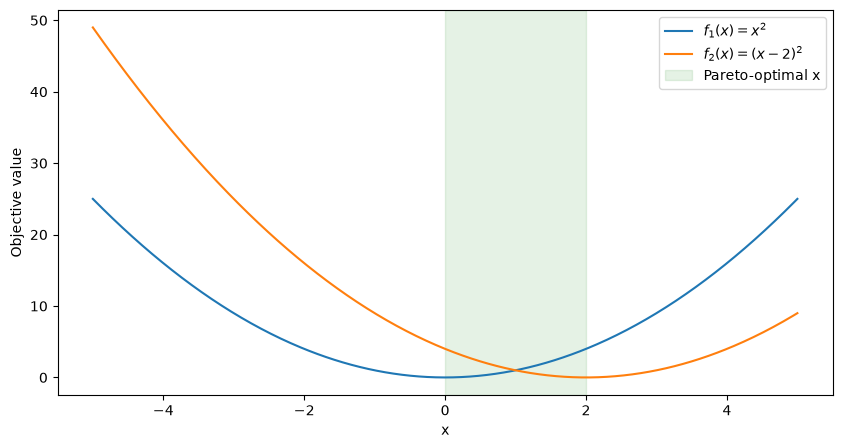

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from thefittest.optimizers import NSGAII, SelfCNSGAII
from thefittest.utils.transformations import GrayCode


def f1(x):
    return x ** 2


def f2(x):
    return (x - 2) ** 2


def problem(X):
    x = X[:, 0]
    return np.column_stack((f1(x), f2(x)))


x = np.linspace(-5, 5, 500)
x_pareto = np.linspace(0, 2, 500)
plt.figure(figsize=(10, 5))
plt.plot(x, f1(x), label=r"$f_1(x) = x^2$")
plt.plot(x, f2(x), label=r"$f_2(x) = (x - 2)^2$")
plt.axvspan(0, 2, alpha=0.1, color="green", label="Pareto-optimal x")
plt.xlabel("x")
plt.ylabel("Objective value")
plt.legend()
plt.show()

In [3]:
encoding = GrayCode()
encoding.fit(left_border=-5., right_border=5., num_variables=1, h_per_variable=0.001)
num_bits = encoding.get_bits_per_variable().sum()
number_of_generations = 200
population_size = 200

## NSGAII

In [4]:
optimizer = NSGAII(
    fitness_function=problem,
    genotype_to_phenotype=encoding.transform,
    iters=number_of_generations,
    pop_size=population_size,
    str_len=num_bits,
    minimization=(True, True),  # Minimize both objective columns.
    show_progress_each=50,
    random_state=42,
)
optimizer.fit()
front = optimizer.get_pareto_front()
print("Pareto front size:", len(front["fitness"]))

0-th iteration with Pareto front size = 42; best objectives = [f1=7.83338e-05, f2=0.000854839]
50-th iteration with Pareto front size = 200; best objectives = [f1=9.31436e-08, f2=3.72575e-09]
100-th iteration with Pareto front size = 200; best objectives = [f1=9.31436e-08, f2=3.72575e-09]
150-th iteration with Pareto front size = 200; best objectives = [f1=9.31436e-08, f2=3.72575e-09]
Pareto front size: 200


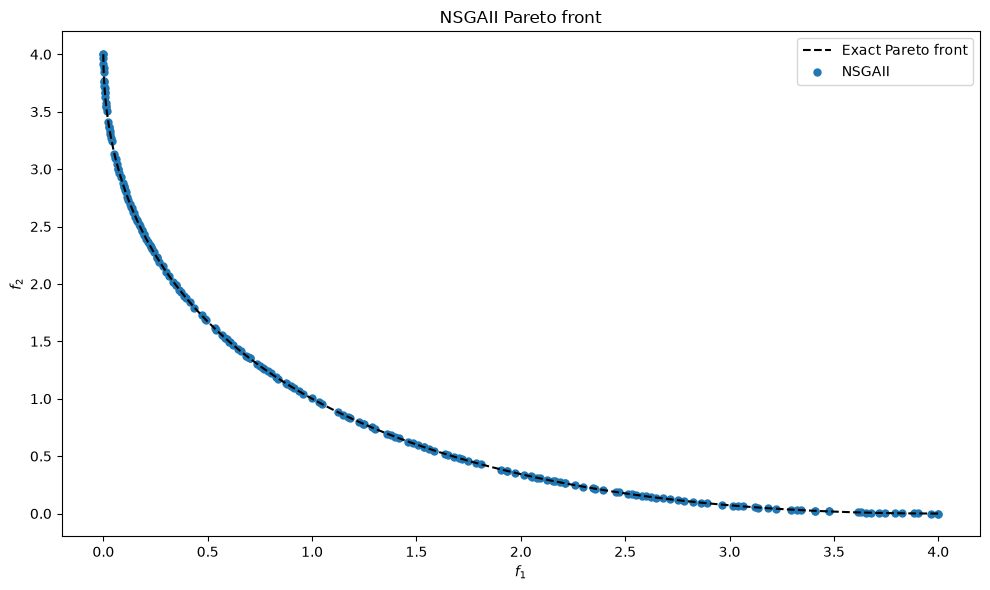

In [5]:
plt.figure(figsize=(10, 6))
plt.plot(f1(x_pareto), f2(x_pareto), "k--", label="Exact Pareto front")
plt.scatter(*front["fitness"].T, s=25, label="NSGAII")
plt.xlabel(r"$f_1$")
plt.ylabel(r"$f_2$")
plt.title("NSGAII Pareto front")
plt.legend()
plt.tight_layout()
plt.show()

## SelfCNSGAII

Operator selection probabilities adapt during optimization.

In [6]:
adaptive_optimizer = SelfCNSGAII(
    fitness_function=problem,
    genotype_to_phenotype=encoding.transform,
    iters=number_of_generations,
    pop_size=population_size,
    str_len=num_bits,
    minimization=(True, True),
    keep_history=True,
    show_progress_each=50,
    random_state=42,
)
adaptive_optimizer.fit()
adaptive_front = adaptive_optimizer.get_pareto_front()
print("Pareto front size:", len(adaptive_front["fitness"]))

0-th iteration with Pareto front size = 42; best objectives = [f1=7.83338e-05, f2=0.000854839]
50-th iteration with Pareto front size = 200; best objectives = [f1=9.31436e-08, f2=3.72575e-09]
100-th iteration with Pareto front size = 200; best objectives = [f1=9.31436e-08, f2=3.72575e-09]
150-th iteration with Pareto front size = 200; best objectives = [f1=9.31436e-08, f2=3.72575e-09]
Pareto front size: 200


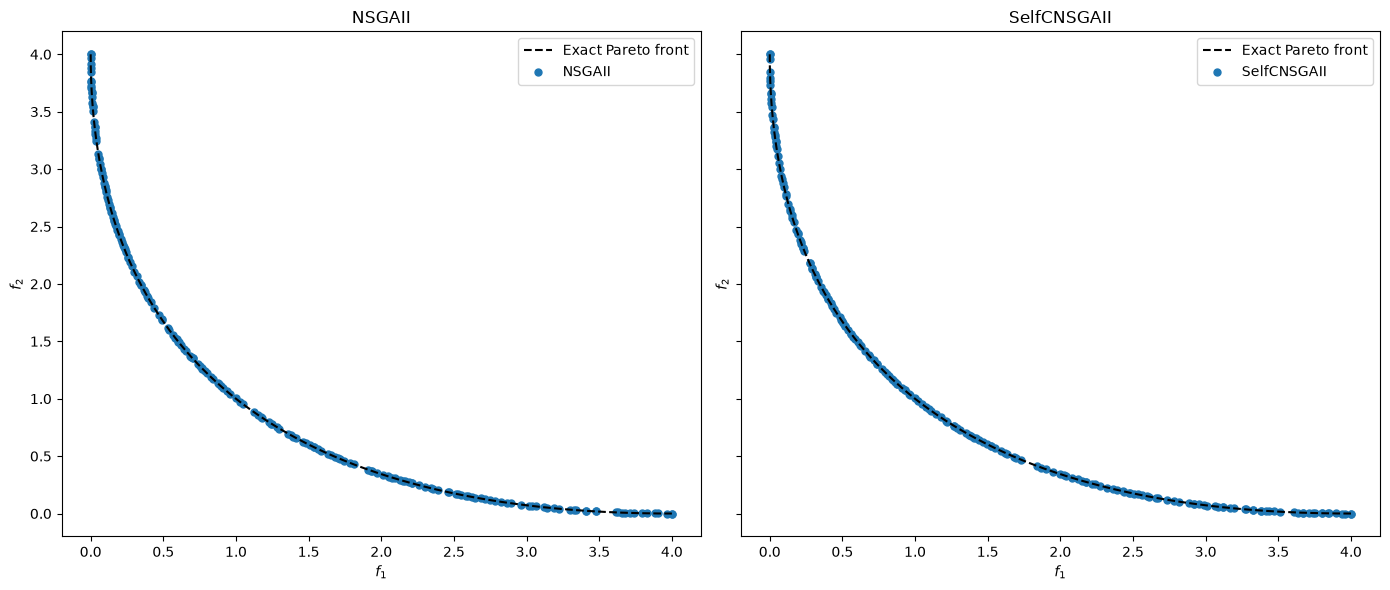

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, result, title in zip(axes, [front, adaptive_front], ["NSGAII", "SelfCNSGAII"]):
    ax.plot(f1(x_pareto), f2(x_pareto), "k--", label="Exact Pareto front")
    ax.scatter(*result["fitness"].T, s=25, label=title)
    ax.set(xlabel=r"$f_1$", ylabel=r"$f_2$", title=title)
    ax.legend()
plt.tight_layout()
plt.show()

## Operator probabilities and Pareto front size

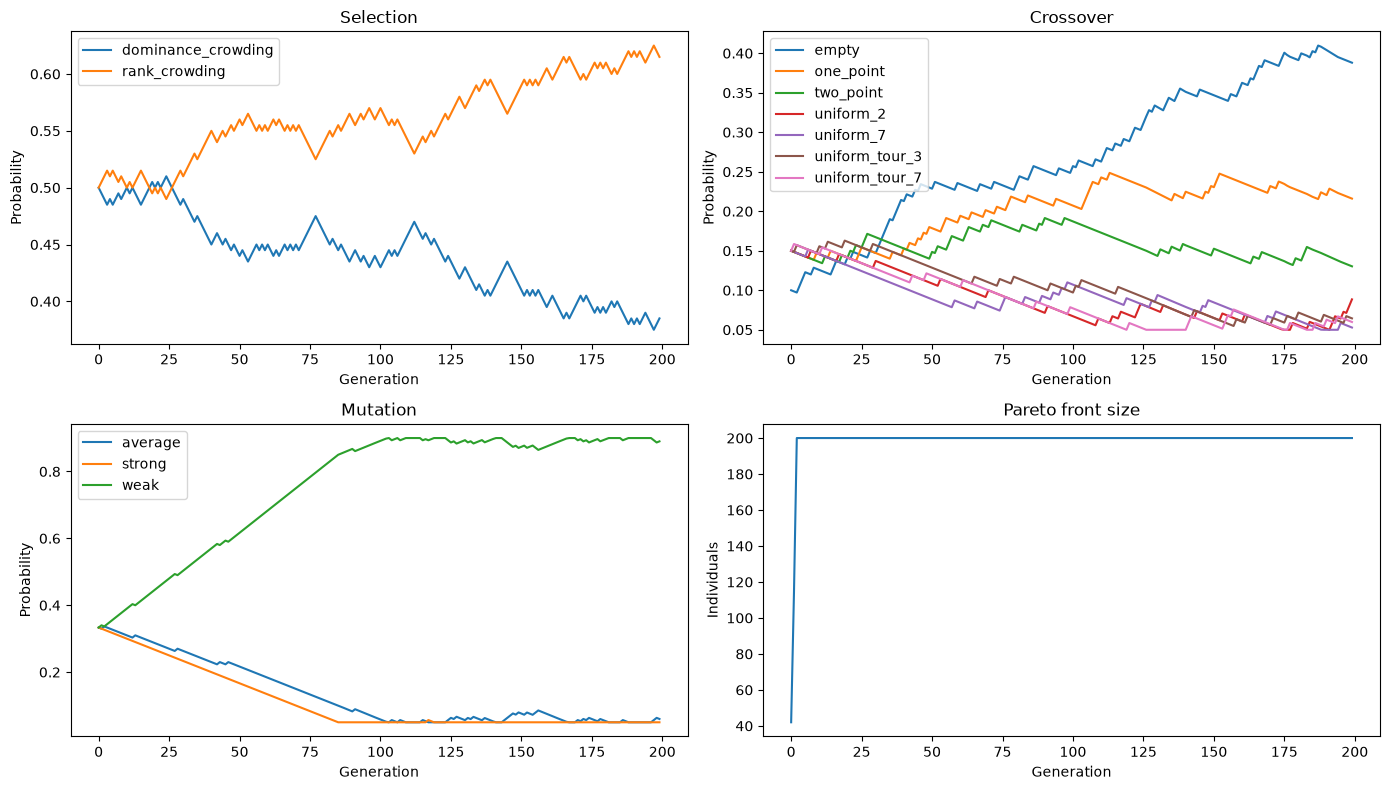

In [8]:
stats = adaptive_optimizer.get_stats()
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, key, title in zip(axes.flat, ["s_proba", "c_proba", "m_proba"],
                          ["Selection", "Crossover", "Mutation"]):
    for operator in stats[key][0]:
        ax.plot([step[operator] for step in stats[key]], label=operator)
    ax.set(title=title, ylabel="Probability")
    ax.legend()
axes[1, 1].plot([np.count_nonzero(rank == 1) for rank in stats["pareto_rank"]])
axes[1, 1].set(title="Pareto front size", ylabel="Individuals")
for ax in axes.flat:
    ax.set_xlabel("Generation")
plt.tight_layout()
plt.show()